## **Library**

In [85]:
import shap
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = [10, 5]
plt.rcParams['axes.grid'] = True
sns.set_theme(style = 'whitegrid')

In [2]:
net_df = pd.read_csv(r"C:\Users\swaro\OneDrive\Documents\RAG\SentinelTrace-AI\dataset\Network_logs.csv")
time_df = pd.read_csv(r"C:\Users\swaro\OneDrive\Documents\RAG\SentinelTrace-AI\dataset\Time-Series_Network_logs.csv")

display(net_df.head())
display(time_df.head())

,Source_IP,Destination_IP,Port,Request_Type,Protocol,Payload_Size,User_Agent,Status,Intrusion,Scan_Type
0,192.168.142.55,42.156.67.167,80,FTP,UDP,2369,curl/7.68.0,Success,0,Normal
1,53.39.165.18,94.60.242.119,135,SMTP,UDP,1536,Wget/1.20.3,Failure,1,BotAttack
2,192.168.127.91,7.10.192.3,21,SMTP,TCP,1183,Wget/1.20.3,Success,0,Normal
3,192.168.30.40,130.169.82.211,25,HTTPS,TCP,666,Mozilla/5.0,Success,0,Normal
4,192.168.43.179,35.140.102.220,22,FTP,TCP,2821,Mozilla/5.0,Success,0,Normal


,Timestamp,Source_IP,Destination_IP,Port,Request_Type,Protocol,Payload_Size,User_Agent,Status,Intrusion,Scan_Type
0,2025-06-06 06:04:08,192.168.54.167,220.159.139.17,443,SSH,ICMP,2954,Mozilla/5.0,Success,0,Normal
1,2025-06-04 15:20:59,192.168.193.254,201.83.205.167,80,FTP,UDP,206,Wget/1.20.3,Success,0,Normal
2,2025-06-03 07:23:49,192.168.91.17,211.0.177.164,21,SSH,ICMP,977,nmap/7.80,Success,0,Normal
3,2025-06-03 11:35:42,192.168.108.75,187.49.21.67,22,HTTP,TCP,521,curl/7.68.0,Success,0,Normal
4,2025-06-05 06:09:02,192.168.245.254,189.62.16.12,53,Telnet,TCP,251,Wget/1.20.3,Success,0,Normal


In [4]:
print("Networks Logs", net_df.shape)
print("Time Series Networks Logs", time_df.shape)

Networks Logs (8846, 10)
Time Series Networks Logs (8866, 11)


In [5]:
print("Networks Logs")
net_df.info()
print("\nTime Series Logs")
time_df.info()

Networks Logs
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8846 entries, 0 to 8845
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Source_IP       8846 non-null   object
 1   Destination_IP  8846 non-null   object
 2   Port            8846 non-null   int64 
 3   Request_Type    8846 non-null   object
 4   Protocol        8846 non-null   object
 5   Payload_Size    8846 non-null   int64 
 6   User_Agent      8846 non-null   object
 7   Status          8846 non-null   object
 8   Intrusion       8846 non-null   int64 
 9   Scan_Type       8846 non-null   object
dtypes: int64(3), object(7)
memory usage: 691.2+ KB

Time Series Logs
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8866 entries, 0 to 8865
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Timestamp       8866 non-null   object
 1   Source_IP       8866 non-null   objec

In [9]:
print("Duplicate Values of Networks Logs")
print(net_df.duplicated().sum())
print("\nDuplicate Values of Time Series Logs")
print(time_df.duplicated().sum())

Duplicate Values of Networks Logs
0

Duplicate Values of Time Series Logs
0


In [10]:
print("Missing Values of Networks Logs")
print(net_df.isnull().sum())
print("\nMissing Values of Time Series Logs")
print(time_df.isnull().sum())

Missing Values of Networks Logs
Source_IP         0
Destination_IP    0
Port              0
Request_Type      0
Protocol          0
Payload_Size      0
User_Agent        0
Status            0
Intrusion         0
Scan_Type         0
dtype: int64

Missing Values of Time Series Logs
Timestamp         0
Source_IP         0
Destination_IP    0
Port              0
Request_Type      0
Protocol          0
Payload_Size      0
User_Agent        0
Status            0
Intrusion         0
Scan_Type         0
dtype: int64


In [11]:
print("Network Logs Intrusion Distribution:")
display(net_df["Intrusion"].value_counts())

print("\nTime Series Intrusion Distribution:")
display(time_df["Intrusion"].value_counts())

Network Logs Intrusion Distribution:


Intrusion
0    8000
1     846
Name: count, dtype: int64


Time Series Intrusion Distribution:


Intrusion
0    8000
1     866
Name: count, dtype: int64

## **EDA**

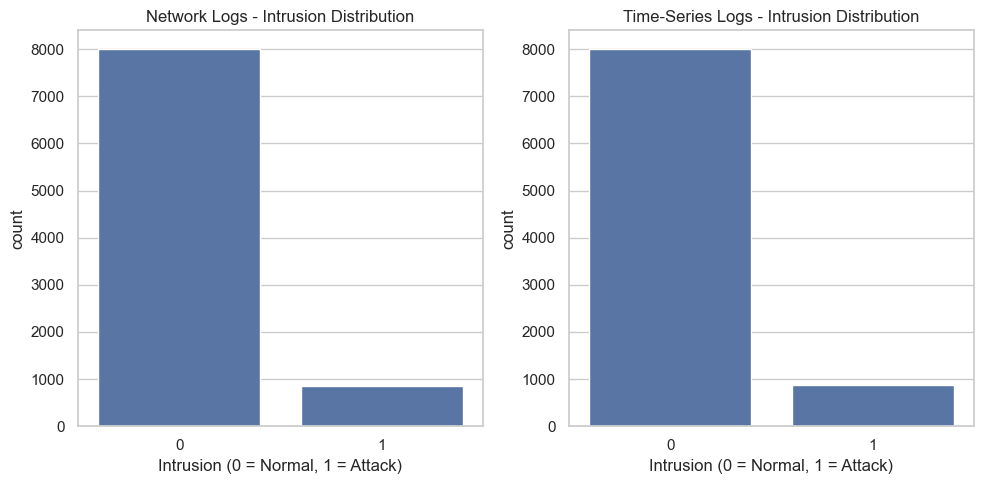

In [12]:
plt.subplot(1,2,1)
sns.countplot(data = net_df, x = 'Intrusion')
plt.title("Network Logs - Intrusion Distribution")
plt.xlabel("Intrusion (0 = Normal, 1 = Attack)")

plt.subplot(1,2,2)
sns.countplot(data = time_df, x = 'Intrusion')
plt.title("Time-Series Logs - Intrusion Distribution")
plt.xlabel("Intrusion (0 = Normal, 1 = Attack)")

plt.tight_layout()
plt.show()

In [14]:
print("Network Logs - Scan Types")
display(net_df["Scan_Type"].value_counts())

print("\nTime-Series Logs - Scan Types")
display(time_df["Scan_Type"].value_counts())

Network Logs - Scan Types


Scan_Type
Normal       8000
BotAttack     478
PortScan      368
Name: count, dtype: int64


Time-Series Logs - Scan Types


Scan_Type
Normal       8000
BotAttack     514
PortScan      352
Name: count, dtype: int64

In [18]:
display(
    pd.crosstab(
        net_df['Intrusion'],
        net_df['Status'],
        margins = True
    )
)

Status,Failure,Success,All
Intrusion,,,
0,385,7615,8000
1,724,122,846
All,1109,7737,8846


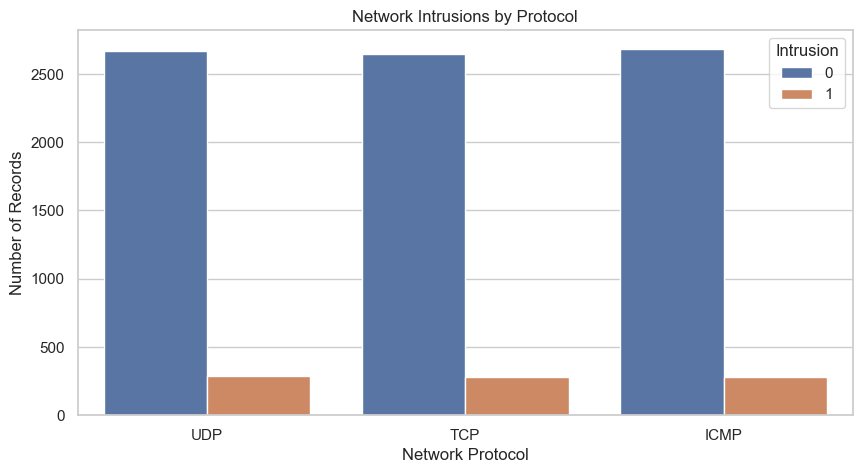

In [19]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=net_df,
    x="Protocol",
    hue="Intrusion"
)

plt.title("Network Intrusions by Protocol")
plt.xlabel("Network Protocol")
plt.ylabel("Number of Records")

plt.show()

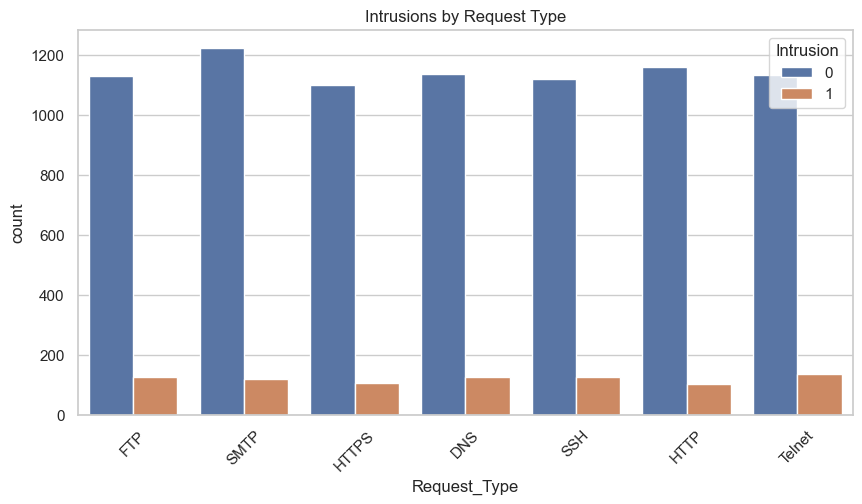

In [20]:
plt.figure(figsize = (10, 5))

sns.countplot(
    data = net_df,
    x = 'Request_Type',
    hue = 'Intrusion'
)

plt.title("Intrusions by Request Type")
plt.xticks(rotation=45)
plt.show()

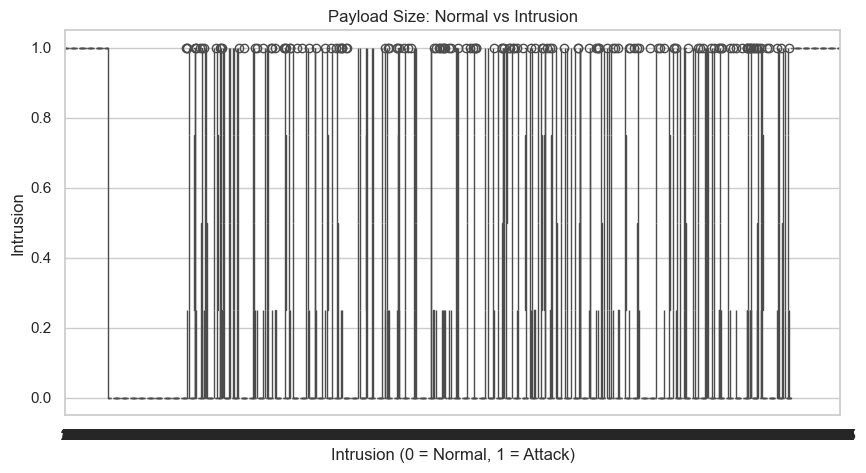

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data = net_df,
    x = "Payload_Size",
    y = 'Intrusion'
)

plt.title("Payload Size: Normal vs Intrusion")
plt.xlabel("Intrusion (0 = Normal, 1 = Attack)")

plt.show()

In [22]:
display(
    pd.crosstab(
        net_df['Scan_Type'],
        net_df['Intrusion'],
        margins = True
    )
)

Intrusion,0,1,All
Scan_Type,,,
BotAttack,0,478,478
Normal,8000,0,8000
PortScan,0,368,368
All,8000,846,8846


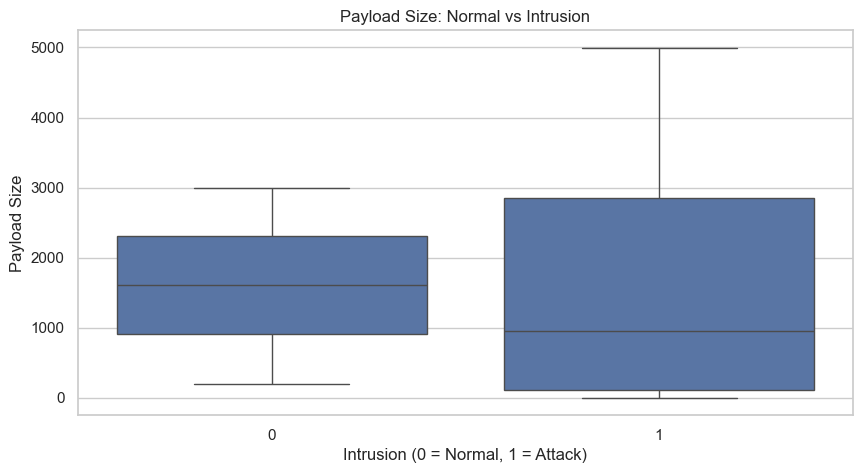

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=net_df,
    x="Intrusion",
    y="Payload_Size"
)

plt.title("Payload Size: Normal vs Intrusion")
plt.xlabel("Intrusion (0 = Normal, 1 = Attack)")
plt.ylabel("Payload Size")

plt.show()

In [24]:
display(
    net_df.groupby("Intrusion")["Payload_Size"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
Intrusion,,,,,,,,
0,8000.0,1603.545875,809.269847,200.0,905.0,1606.5,2306.00,3000.0
1,846.0,1553.533097,1604.215295,0.0,113.0,958.5,2855.75,4997.0


In [25]:
protocol_analysis = pd.crosstab(
    net_df["Protocol"],
    net_df["Intrusion"],
    normalize="index"
) * 100

display(protocol_analysis.round(2))

Intrusion,0,1
Protocol,,
ICMP,90.65,9.35
TCP,90.45,9.55
UDP,90.21,9.79


In [26]:
port_analysis = (
    net_df.groupby("Port")["Intrusion"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

port_analysis.columns = [
    "Total_Requests",
    "Intrusion_Count",
    "Intrusion_Rate"
]

display(port_analysis.head(15))

,Total_Requests,Intrusion_Count,Intrusion_Rate
Port,,,
23,155,155,1.0
135,121,121,1.0
4444,153,153,1.0
6667,134,134,1.0
8080,148,148,1.0
31337,135,135,1.0
21,1343,0,0.0
22,1387,0,0.0
25,1311,0,0.0


In [27]:
port_check = pd.crosstab(
    net_df["Port"],
    net_df["Intrusion"]
)

display(port_check)

Intrusion,0,1
Port,,
21,1343,0
22,1387,0
23,0,155
25,1311,0
53,1339,0
80,1364,0
135,0,121
443,1256,0
4444,0,153


In [28]:
print("Unique ports:", net_df["Port"].nunique())

print("\nIntrusion rate by port:")
display(
    net_df.groupby("Port")["Intrusion"]
    .mean()
    .sort_values(ascending=False)
)

Unique ports: 12

Intrusion rate by port:


Port
23       1.0
135      1.0
4444     1.0
6667     1.0
8080     1.0
31337    1.0
21       0.0
22       0.0
25       0.0
53       0.0
80       0.0
443      0.0
Name: Intrusion, dtype: float64

In [29]:
quality_report = pd.DataFrame({
    "Dataset": ["Network Logs", "Time-Series Logs"],
    "Missing_Values": [
        net_df.isnull().sum().sum(),
        time_df.isnull().sum().sum()
    ],
    "Duplicate_Rows": [
        net_df.duplicated().sum(),
        time_df.duplicated().sum()
    ],
    "Total_Rows": [
        len(net_df),
        len(time_df)
    ]
})

display(quality_report)

,Dataset,Missing_Values,Duplicate_Rows,Total_Rows
0,Network Logs,0,0,8846
1,Time-Series Logs,0,0,8866


In [30]:
ip_analysis = (
    net_df.groupby("Source_IP")
    .agg(
        Total_Requests=("Intrusion", "count"),
        Intrusion_Count=("Intrusion", "sum")
    )
)

ip_analysis["Intrusion_Rate"] = (
    ip_analysis["Intrusion_Count"] /
    ip_analysis["Total_Requests"]
) * 100

display(
    ip_analysis.sort_values(
        "Intrusion_Rate",
        ascending=False
    ).head(15).round(2)
)

,Total_Requests,Intrusion_Count,Intrusion_Rate
Source_IP,,,
154.113.2.100,57,57,100.0
161.77.134.239,45,45,100.0
94.40.34.8,48,48,100.0
78.199.98.120,56,56,100.0
53.39.165.18,35,35,100.0
33.5.52.172,58,58,100.0
219.110.174.163,44,44,100.0
216.181.134.4,46,46,100.0
214.63.186.119,36,36,100.0


In [31]:
destination_analysis = (
    net_df.groupby("Destination_IP")
    .agg(
        Total_Requests=("Intrusion", "count"),
        Intrusion_Count=("Intrusion", "sum")
    )
)

destination_analysis["Intrusion_Rate"] = (
    destination_analysis["Intrusion_Count"] /
    destination_analysis["Total_Requests"]
) * 100

display(
    destination_analysis.sort_values(
        "Intrusion_Count",
        ascending=False
    ).head(15).round(2)
)

,Total_Requests,Intrusion_Count,Intrusion_Rate
Destination_IP,,,
200.233.1.140,1,1,100.0
217.241.166.138,1,1,100.0
194.88.166.189,1,1,100.0
57.86.127.223,1,1,100.0
172.214.181.188,1,1,100.0
188.163.66.230,1,1,100.0
156.196.252.218,1,1,100.0
205.9.87.23,1,1,100.0
194.57.227.24,1,1,100.0


In [32]:
source_ip_check = pd.crosstab(
    net_df["Source_IP"],
    net_df["Intrusion"]
)

source_ip_check.columns = [
    "Normal",
    "Intrusion"
]

source_ip_check["Total"] = (
    source_ip_check["Normal"] +
    source_ip_check["Intrusion"]
)

source_ip_check["IP_Category"] = source_ip_check.apply(
    lambda row: (
        "Mixed Traffic"
        if row["Normal"] > 0 and row["Intrusion"] > 0
        else "Only Normal"
        if row["Normal"] > 0
        else "Only Intrusion"
    ),
    axis=1
)

display(source_ip_check["IP_Category"].value_counts())

IP_Category
Only Normal       7545
Only Intrusion      20
Name: count, dtype: int64

In [33]:
destination_ip_check = pd.crosstab(
    net_df["Destination_IP"],
    net_df["Intrusion"]
)

display(
    destination_ip_check[
        (destination_ip_check[0] > 0) &
        (destination_ip_check[1] > 0)
    ].head(15)
)

print(
    "Total unique destination IPs:",
    net_df["Destination_IP"].nunique()
)

Intrusion,0,1
Destination_IP,,


Total unique destination IPs: 8846


In [34]:
# Remove features that may cause target leakage

drop_columns = [
    "Source_IP",
    "Destination_IP",
    "Port",
    "Scan_Type"
]

model_df = net_df.drop(columns=drop_columns)

print("Original dataset shape:", net_df.shape)
print("Modelling dataset shape:", model_df.shape)

display(model_df.head())

Original dataset shape: (8846, 10)
Modelling dataset shape: (8846, 6)


,Request_Type,Protocol,Payload_Size,User_Agent,Status,Intrusion
0,FTP,UDP,2369,curl/7.68.0,Success,0
1,SMTP,UDP,1536,Wget/1.20.3,Failure,1
2,SMTP,TCP,1183,Wget/1.20.3,Success,0
3,HTTPS,TCP,666,Mozilla/5.0,Success,0
4,FTP,TCP,2821,Mozilla/5.0,Success,0


In [35]:
print("Remaining columns:")
print(model_df.columns.tolist())

print("\nTarget distribution:")
display(model_df["Intrusion"].value_counts())

Remaining columns:
['Request_Type', 'Protocol', 'Payload_Size', 'User_Agent', 'Status', 'Intrusion']

Target distribution:


Intrusion
0    8000
1     846
Name: count, dtype: int64

In [36]:
categorical_columns = [
    "Request_Type",
    "Protocol",
    "User_Agent",
    "Status"
]

for col in categorical_columns:

    print(f"\nIntrusion distribution by {col}:")

    display(
        pd.crosstab(
            model_df[col],
            model_df["Intrusion"],
            normalize="index"
        ).round(3) * 100
    )


Intrusion distribution by Request_Type:


Intrusion,0,1
Request_Type,,
DNS,89.9,10.1
FTP,90.0,10.0
HTTP,91.8,8.2
HTTPS,91.2,8.8
SMTP,91.0,9.0
SSH,89.8,10.2
Telnet,89.4,10.6



Intrusion distribution by Protocol:


Intrusion,0,1
Protocol,,
ICMP,90.7,9.3
TCP,90.5,9.5
UDP,90.2,9.8



Intrusion distribution by User_Agent:


Intrusion,0,1
User_Agent,,
Mozilla/5.0,90.5,9.5
Nikto/2.1.6,90.1,9.9
Wget/1.20.3,90.7,9.3
curl/7.68.0,90.0,10.0
nmap/7.80,90.0,10.0
python-requests/2.25.1,91.3,8.7



Intrusion distribution by Status:


Intrusion,0,1
Status,,
Failure,34.7,65.3
Success,98.4,1.6


In [37]:
display(
    model_df.groupby("Intrusion")["Payload_Size"].describe()
)

,count,mean,std,min,25%,50%,75%,max
Intrusion,,,,,,,,
0,8000.0,1603.545875,809.269847,200.0,905.0,1606.5,2306.00,3000.0
1,846.0,1553.533097,1604.215295,0.0,113.0,958.5,2855.75,4997.0


In [38]:
payload_analysis = model_df.groupby("Intrusion")["Payload_Size"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(payload_analysis.round(2))

,count,mean,median,std,min,max
Intrusion,,,,,,
0,8000,1603.55,1606.5,809.27,200,3000
1,846,1553.53,958.5,1604.22,0,4997


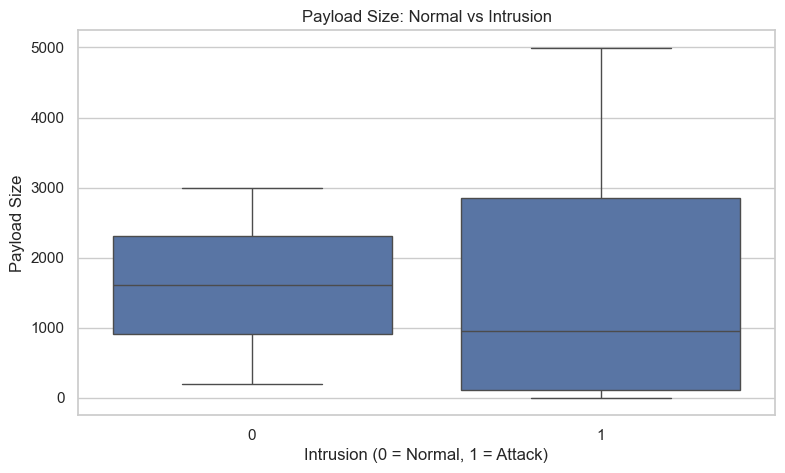

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=model_df,
    x="Intrusion",
    y="Payload_Size"
)

plt.title("Payload Size: Normal vs Intrusion")
plt.xlabel("Intrusion (0 = Normal, 1 = Attack)")
plt.ylabel("Payload Size")

plt.show()

## **Train Test Split**

In [42]:
X = model_df.drop("Intrusion", axis = 1)
y = model_df['Intrusion']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Features shape: (8846, 5)
Target shape: (8846,)
Training data: (7076, 5)
Testing data: (1770, 5)

Training target distribution:
Intrusion
0    90.432448
1     9.567552
Name: proportion, dtype: float64

Testing target distribution:
Intrusion
0    90.451977
1     9.548023
Name: proportion, dtype: float64


In [43]:
# Identify categorical and numerical columns

categorical_features = [
    "Request_Type",
    "Protocol",
    "User_Agent",
    "Status"
]

numerical_features = [
    "Payload_Size"
]

# Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing configuration created successfully.")

Preprocessing configuration created successfully.


In [44]:
log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [47]:
lr_pred = log_model.predict(X_test)

lr_prob = log_model.predict_proba(X_test)[:, 1]

In [48]:
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Accuracy: 0.9350282485875706
Precision: 0.6163793103448276
Recall: 0.8461538461538461
F1 Score: 0.713216957605985
ROC-AUC: 0.9223894829045456

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96      1601
           1       0.62      0.85      0.71       169

    accuracy                           0.94      1770
   macro avg       0.80      0.90      0.84      1770
weighted avg       0.95      0.94      0.94      1770


Confusion Matrix:
[[1512   89]
 [  26  143]]


In [50]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=5,
        random_state=42
    ))
])

# Train model
dt_model.fit(X_train, y_train)

# Predictions
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Accuracy: 0.9457627118644067
Precision: 0.6553191489361702
Recall: 0.9112426035502958
F1 Score: 0.7623762376237624
ROC-AUC: 0.9545790537718659

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1601
           1       0.66      0.91      0.76       169

    accuracy                           0.95      1770
   macro avg       0.82      0.93      0.87      1770
weighted avg       0.96      0.95      0.95      1770


Confusion Matrix:
[[1520   81]
 [  15  154]]


In [52]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy: 0.9463276836158192
Precision: 0.6581196581196581
Recall: 0.9112426035502958
F1 Score: 0.7642679900744417
ROC-AUC: 0.937304347504703

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1601
           1       0.66      0.91      0.76       169

    accuracy                           0.95      1770
   macro avg       0.82      0.93      0.87      1770
weighted avg       0.96      0.95      0.95      1770


Confusion Matrix:
[[1521   80]
 [  15  154]]


In [53]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, log_model.predict(X_test)),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, log_model.predict(X_test)),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, log_model.predict(X_test)),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, log_model.predict(X_test)),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, log_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9350,0.6164,0.8462,0.7132,0.9224
1,Decision Tree,0.9458,0.6553,0.9112,0.7624,0.9546
2,Random Forest,0.9463,0.6581,0.9112,0.7643,0.9373


In [55]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [57]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [58]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=skf,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9454,0.6651,0.8671,0.7526,0.9351
1,Decision Tree,0.9541,0.6991,0.9158,0.7926,0.9502
2,Random Forest,0.9565,0.7180,0.8981,0.7980,0.9561


In [60]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300, 500],

    "classifier__max_depth": [None, 5, 10, 15, 20],

    "classifier__min_samples_split": [2, 5, 10],

    "classifier__min_samples_leaf": [1, 2, 4],

    "classifier__max_features": ["sqrt", "log2"],

    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

In [61]:
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [62]:
rf_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(rf_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1 Score:
0.7979549426567937


In [63]:
best_rf_model = rf_search.best_estimator_

print("Best Random Forest model selected!")

Best Random Forest model selected!


In [64]:
y_pred_tuned = best_rf_model.predict(X_test)

y_prob_tuned = best_rf_model.predict_proba(X_test)[:, 1]

In [65]:
print("Tuned Random Forest Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("Precision:", precision_score(y_test, y_pred_tuned))

print("Recall:", recall_score(y_test, y_pred_tuned))

print("F1 Score:", f1_score(y_test, y_pred_tuned))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Random Forest Performance
Accuracy: 0.9463276836158192
Precision: 0.6581196581196581
Recall: 0.9112426035502958
F1 Score: 0.7642679900744417
ROC-AUC: 0.937304347504703

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1601
           1       0.66      0.91      0.76       169

    accuracy                           0.95      1770
   macro avg       0.82      0.93      0.87      1770
weighted avg       0.96      0.95      0.95      1770


Confusion Matrix:
[[1521   80]
 [  15  154]]


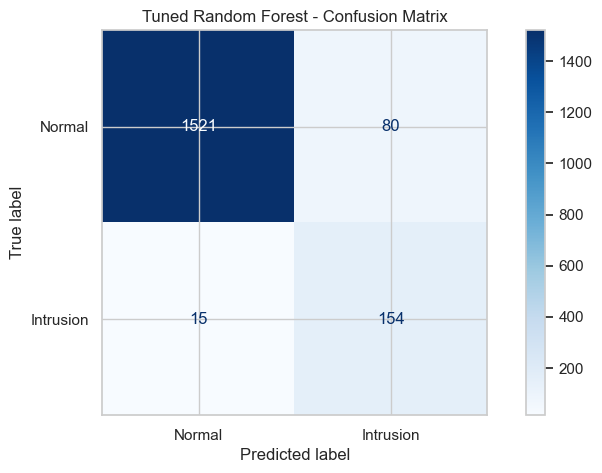

In [67]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Normal", "Intrusion"],
    cmap="Blues"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

In [70]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    best_rf_model,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [72]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Best F1 Score:", f1_scores[best_index])
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])

Best Threshold: 0.5084468118002851
Best F1 Score: 0.7999999999505962
Precision: 0.7212336892052195
Recall: 0.8980797636632201


In [73]:
y_pred_optimized = (
    y_prob_tuned >= best_threshold
).astype(int)

print("Optimised Threshold:", best_threshold)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimized))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimized))

Optimised Threshold: 0.5084468118002851

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1601
           1       0.66      0.91      0.76       169

    accuracy                           0.95      1770
   macro avg       0.82      0.93      0.87      1770
weighted avg       0.96      0.95      0.95      1770


Confusion Matrix:
[[1521   80]
 [  15  154]]


In [74]:
default_predictions = (y_prob_tuned >= 0.5).astype(int)

optimized_predictions = (
    y_prob_tuned >= best_threshold
).astype(int)

print("Default predictions:", np.sum(default_predictions))
print("Optimised predictions:", np.sum(optimized_predictions))

print(
    "Changed predictions:",
    np.sum(default_predictions != optimized_predictions)
)

Default predictions: 234
Optimised predictions: 234
Changed predictions: 0


In [80]:
# Extract transformed feature names
feature_names = (
    best_rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance
rf_estimator = best_rf_model.named_steps["classifier"]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
17,cat__Status_Failure,0.407913
0,num__Payload_Size,0.277738
18,cat__Status_Success,0.267636
10,cat__Protocol_UDP,0.004975
9,cat__Protocol_TCP,0.004195
14,cat__User_Agent_curl/7.68.0,0.004177
8,cat__Protocol_ICMP,0.003935
7,cat__Request_Type_Telnet,0.003008
4,cat__Request_Type_HTTPS,0.002818
13,cat__User_Agent_Wget/1.20.3,0.002790


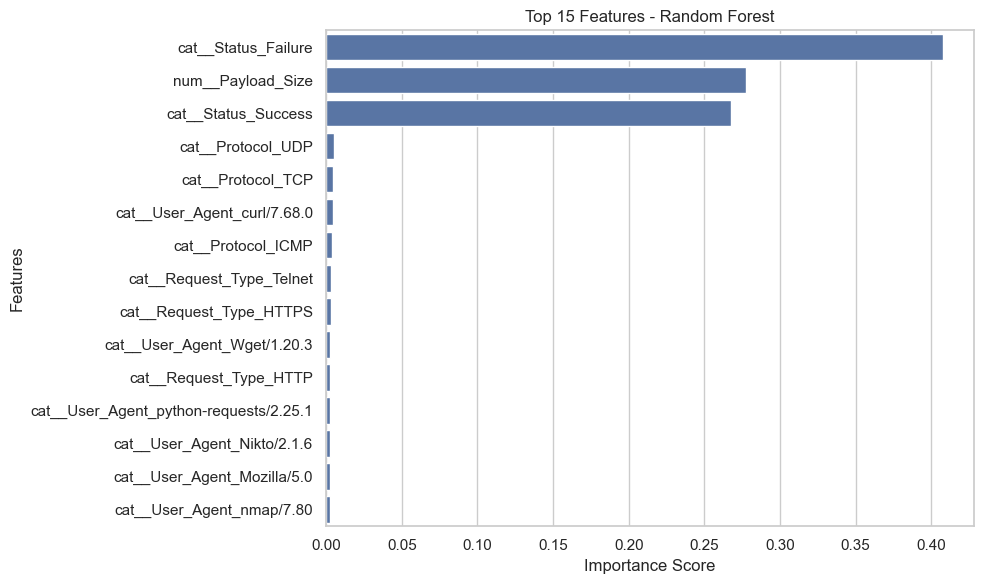

In [81]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [89]:
from scipy import sparse
import numpy as np

if sparse.issparse(X_test_transformed):
    X_test_numeric = X_test_transformed.toarray()
else:
    X_test_numeric = np.asarray(X_test_transformed)

X_test_numeric = X_test_numeric.astype(np.float64)

print("Data type:", X_test_numeric.dtype)
print("Shape:", X_test_numeric.shape)

Data type: float64
Shape: (1770, 19)


In [93]:
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test_numeric)

print("SHAP calculation completed!")
print("SHAP output type:", type(shap_values))
print("SHAP output shape:", np.array(shap_values).shape)

SHAP calculation completed!
SHAP output type: <class 'numpy.ndarray'>
SHAP output shape: (1770, 19, 2)


In [94]:
preprocessor = best_rf_model.named_steps["preprocessor"]
rf_model = best_rf_model.named_steps["classifier"]

X_test_transformed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Transformed test shape:", X_test_transformed.shape)
print("Number of feature names:", len(feature_names))

Transformed test shape: (1770, 19)
Number of feature names: 19


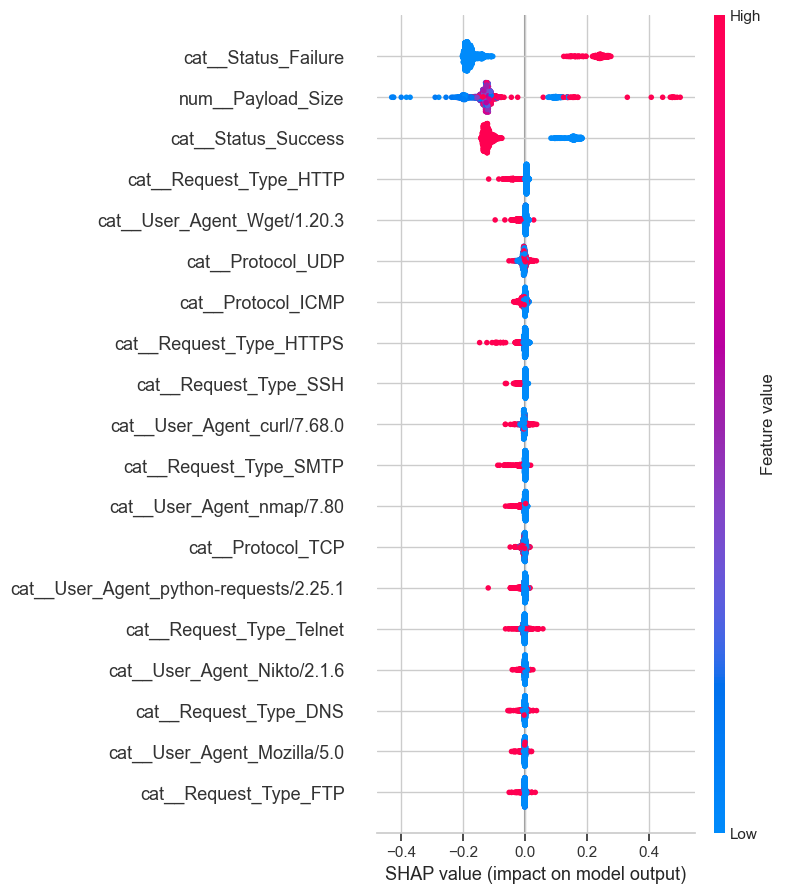

In [96]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_numeric,
    feature_names=feature_names,
    show=True
)

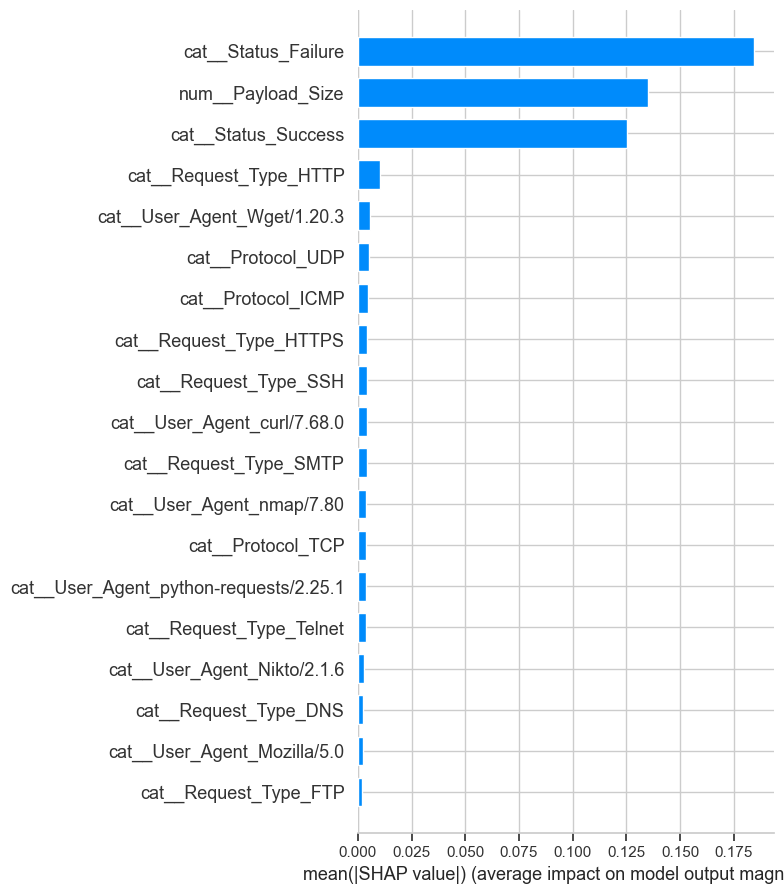

In [97]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_numeric,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)


In [99]:
# Check feature importance percentages
feature_importance["Importance_Percentage"] = (
    feature_importance["Importance"] * 100
)

display(feature_importance)

# Check the threshold difference
print("Default threshold:", 0.5)
print("Optimized threshold:", best_threshold)

print(
    "Changed predictions:",
    np.sum(default_predictions != optimized_predictions)
)

,Feature,Importance,Importance_Percentage
17,cat__Status_Failure,0.407913,40.791309
0,num__Payload_Size,0.277738,27.773815
18,cat__Status_Success,0.267636,26.763560
10,cat__Protocol_UDP,0.004975,0.497539
9,cat__Protocol_TCP,0.004195,0.419490
14,cat__User_Agent_curl/7.68.0,0.004177,0.417655
8,cat__Protocol_ICMP,0.003935,0.393517
7,cat__Request_Type_Telnet,0.003008,0.300800
4,cat__Request_Type_HTTPS,0.002818,0.281778
13,cat__User_Agent_Wget/1.20.3,0.002790,0.278952


Default threshold: 0.5
Optimized threshold: 0.5084468118002851
Changed predictions: 0


In [100]:
# Inspect probabilities around the two thresholds

print("Minimum probability:", y_prob_tuned.min())
print("Maximum probability:", y_prob_tuned.max())

print(
    "Probabilities between 0.50 and 0.5084:",
    np.sum(
        (y_prob_tuned >= 0.5) &
        (y_prob_tuned < best_threshold)
    )
)

print(
    "Probabilities between 0.5084 and 0.52:",
    np.sum(
        (y_prob_tuned >= best_threshold) &
        (y_prob_tuned < 0.52)
    )
)

Minimum probability: 0.005689502169656008
Maximum probability: 0.9990994515661611
Probabilities between 0.50 and 0.5084: 0
Probabilities between 0.5084 and 0.52: 4


In [101]:
# Final test-set evaluation using the selected threshold

test_predictions = (
    y_prob_tuned >= best_threshold
).astype(int)

print("Final Test Accuracy:",
      accuracy_score(y_test, test_predictions))

print("Final Test Precision:",
      precision_score(y_test, test_predictions))

print("Final Test Recall:",
      recall_score(y_test, test_predictions))

print("Final Test F1:",
      f1_score(y_test, test_predictions))

print("Final Test ROC-AUC:",
      roc_auc_score(y_test, y_prob_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Final Test Accuracy: 0.9463276836158192
Final Test Precision: 0.6581196581196581
Final Test Recall: 0.9112426035502958
Final Test F1: 0.7642679900744417
Final Test ROC-AUC: 0.937304347504703

Confusion Matrix:
[[1521   80]
 [  15  154]]


In [102]:
import joblib

# Save the complete trained pipeline
joblib.dump(best_rf_model, "sentineltrace_rf_pipeline.pkl")

print("Model pipeline saved successfully!")

Model pipeline saved successfully!


In [103]:
loaded_model = joblib.load("sentineltrace_rf_pipeline.pkl")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [104]:
# Generate predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare with original predictions
print("Predictions match:",
      (loaded_predictions == test_predictions).all())

Predictions match: True
